# Example 5.1 — From a drug to its analogues to their targets (sildenafil)

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:46Z
- **Contents:** 1 exchange · 6 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/5.1-repurposing-from-analogues-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 5.1-repurposing-from-analogues-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 5.1-repurposing-from-analogues-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/5.1-repurposing-from-analogues-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 5.1-repurposing-from-analogues-notebook-rerun.ipynb 5.1-repurposing-from-analogues-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Start from sildenafil: find its close analogues in BindingDB and tell me which targets besides PDE5 they hit.

In [ ]:
# Call 1 · chemical_name_to_smiles · ran 2026-11-24 04:55:35 UTC
await replay.call(1, 'chemical_name_to_smiles', {'name': 'sildenafil'},
                  sha256='6dcab2240b2483b036378f5df48420d7601a718b7aeb6b32d47dbe668a3b1889')

**Call 1** · `chemical_name_to_smiles` · recorded result · sha256 `6dcab2240b24…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| sildenafil | CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C |

```json
{
  "query": "sildenafil",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C",
  "inchi_key": "BNRNXUUZRGQAQC-UHFFFAOYSA-N",
  "monomerid": 14390,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 14390 | BDBM14390 | Viagra | BNRNXUUZRGQAQC-UHFFFAOYSA-N | CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C | 201 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 2 · similarity_search · ran 2026-11-24 04:55:43 UTC
arguments = {
    'smiles': 'CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C',
    'threshold': 0.7,
    'summarize_by_target': True,
    'max_value_nm': 10000,
    'limit': 100,
}
await replay.call(2, 'similarity_search', arguments,
                  sha256='1cfb705f8670389cb9d9e3e39750babd71337f630fbc34a37aeec6cebd08ae1b')

**Call 2** · `similarity_search` · recorded result · sha256 `1cfb705f8670…`

| name | smiles |
| --- | --- |
| query | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12 |

```json
{
  "query": {
    "input": "CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C",
    "canonical": "CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12",
    "threshold": 0.7,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 35,
  "n_targets": 40,
  "n_compounds_measured": 35,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_40 rows_

| target_kind | target_id | target_name | uniprot_raw | organism | n_compounds | n_measurements | affinity_types | best_p_affinity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 5066 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | 35 | 116 | EC50, IC50, Ki | 9.96 |
| polymer | 2556 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | 4 | 4 | IC50 | 7.06 |
| complex | 50000902 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1B/Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1C/Phosphodiesterase |  |  | 4 | 5 | IC50 | 6.96 |
| polymer | 1967 | Histone deacetylase 1 | Q13547 | Homo sapiens | 3 | 3 | IC50 | 8.1 |
| polymer | 2482 | Histone deacetylase 2 | Q92769 | Homo sapiens | 3 | 3 | IC50 | 6.93 |
| polymer | 50002272 | cGMP-specific 3',5'-cyclic phosphodiesterase | O54735 | Rattus norvegicus | 1 | 3 | IC50, Ki | 9.52 |
| polymer | 50006512 | cGMP-specific 3',5'-cyclic phosphodiesterase | O77746 | Canis lupus familiaris | 1 | 2 | IC50 | 9 |
| polymer | 1577 | cGMP-specific 3',5'-cyclic phosphodiesterase \[531-875\] | O76074\[531-875\] | Homo sapiens | 1 | 1 | IC50 | 8.66 |
| polymer | 1635 | cGMP-specific 3',5'-cyclic phosphodiesterase \[535-860\] | O76074\[535-860\] | Homo sapiens | 1 | 1 | IC50 | 8.62 |
| polymer | 1636 | cGMP-specific 3',5'-cyclic phosphodiesterase \[1-662,679-875\] | O76074\[1-662,679-875\] | Homo sapiens | 1 | 1 | IC50 | 8.23 |
| polymer | 50000786 | cGMP-specific 3',5'-cyclic phosphodiesterase | Q28156 | Bos taurus | 1 | 6 | IC50 | 8.22 |
| complex | 50000813 | O43924/P16499/P18545/P35913/P51160/Q13956 |  |  | 1 | 3 | IC50, Ki | 8.02 |
| complex | 50000741 | P04972/P11541/P16586/P22571/P23439/Q95142 |  |  | 1 | 5 | IC50 | 7.7 |
| polymer | 7940 | Cone cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha' | P51160 | Homo sapiens | 1 | 4 | IC50 | 7.62 |
| complex | 50005049 | Cone cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha'/cGMP-specific 3',5'-cyclic phosphodiesterase |  |  | 1 | 2 | Ki | 7.6 |
| polymer | 1540 | Retinal rod rhodopsin-sensitive cGMP 3',5'-cyclic phosphodiesterase subunit gamma | P54827 | Canis lupus familiaris | 1 | 1 | IC50 | 7.48 |
| complex | 50000007 | Histone deacetylase 3/Nuclear receptor corepressor 2 (HDAC3/NCoR2) |  |  | 1 | 1 | IC50 | 7.44 |
| polymer | 10157 | Rod cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha | P11541 | Bos taurus | 1 | 1 | IC50 | 6.85 |
| polymer | 1639 | cGMP-specific 3',5'-cyclic phosphodiesterase \[1-660,682-875\] | O76074\[1-660,682-875\] | Homo sapiens | 1 | 1 | IC50 | 6.73 |
| polymer | 2130 | Adenosine receptor A2a | P29274 | Homo sapiens | 1 | 1 | Ki | 6.7 |
| complex | 50000731 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B/1C |  |  | 1 | 4 | IC50 | 6.57 |
| complex | 50000743 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B |  |  | 1 | 4 | IC50 | 6.4 |
| polymer | 7465 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A | P54750 | Homo sapiens | 1 | 1 | IC50 | 6.22 |
| polymer | 50006081 | ATP-binding cassette sub-family C member 5 | O15440 | Homo sapiens | 1 | 1 | Ki | 5.92 |
| polymer | 1572 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1B | Q01064 | Homo sapiens | 1 | 1 | IC50 | 5.82 |
| polymer | 7417 | Dual 3',5'-cyclic-AMP and -GMP phosphodiesterase 11A | Q9HCR9 | Homo sapiens | 1 | 5 | IC50 | 5.64 |
| polymer | 5461 | cAMP and cAMP-inhibited cGMP 3',5'-cyclic phosphodiesterase 10A | Q9Y233 | Homo sapiens | 1 | 2 | IC50 | 5.51 |
| polymer | 2132 | Potassium voltage-gated channel subfamily H member 2 | Q12809 | Homo sapiens | 1 | 5 | IC50 | 5.48 |
| polymer | 5068 | High affinity cGMP-specific 3',5'-cyclic phosphodiesterase 9A | O76083 | Homo sapiens | 1 | 2 | IC50 | 5.47 |
| polymer | 50006244 | Indoleamine 2,3-dioxygenase 2 | Q8R0V5 | Mus musculus | 1 | 1 | IC50 | 5.35 |
| complex | 50006150 | cAMP-specific 3',5'-cyclic phosphodiesterase 4A/4B/4C/4D |  |  | 1 | 1 | IC50 | 5.34 |
| polymer | 6027 | High affinity cAMP-specific 3',5'-cyclic phosphodiesterase 7A | Q13946 | Homo sapiens | 1 | 1 | IC50 | 5.33 |
| polymer | 1180 | cAMP-specific 3',5'-cyclic phosphodiesterase 4A | P27815 | Homo sapiens | 1 | 1 | IC50 | 5.3 |
| polymer | 1580 | High affinity cGMP-specific 3',5'-cyclic phosphodiesterase 9A \[226-593\] | O76083\[226-593\] | Homo sapiens | 1 | 1 | IC50 | 5.25 |
| polymer | 1582 | Isoform 4 of Dual 3',5'-cyclic-AMP and -GMP phosphodiesterase 11A (PDE11A1) 35-489\] | Q9HCR9-4\[135-489\] | Homo sapiens | 1 | 1 | IC50 | 5.21 |
| polymer | 1581 | cAMP and cAMP-inhibited cGMP 3',5'-cyclic phosphodiesterase 10A \[432-779\] | Q9Y233\[432-779\] | Homo sapiens | 1 | 1 | IC50 | 5.17 |
| complex | 50000730 | cGMP-inhibited 3',5'-cyclic phosphodiesterase 3A/3B |  |  | 1 | 2 | IC50 | 5.15 |
| complex | 50000012 | cAMP-specific 3',5'-cyclic phosphodiesterase 4A/4B/4C/4D |  |  | 1 | 2 | IC50 | 5.11 |
| polymer | 770 | Replicase polyprotein 1ab | P0DTD1 | Severe acute respiratory syndrome coronavirus 2 | 1 | 1 | IC50 | 5.08 |
| polymer | 50002848 | Phosphodiesterase |  | Bos taurus | 1 | 2 | IC50 | 5.04 |


In [ ]:
# Call 3 · similarity_search · ran 2026-11-24 04:55:43 UTC
arguments = {
    'smiles': 'CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C',
    'threshold': 0.7,
    'limit': 100,
}
await replay.call(3, 'similarity_search', arguments,
                  sha256='5ae582e6668931a986775477f43771f3fdf2d5a94aa46b225ef0cc82fc1b76ad')

**Call 3** · `similarity_search` · recorded result · sha256 `5ae582e66689…`

| name | smiles |
| --- | --- |
| query | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12 |

```json
{
  "query": {
    "input": "CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C",
    "canonical": "CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12",
    "threshold": 0.7,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 35,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_35 rows_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 14390 | BDBM14390 | Viagra | CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C | 474.2 | 201 | 58 | 1 |
| 50238854 | BDBM50238854 | Viagra | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(C)CC4)ccc3OCC)nc12 | 474.2 | 8 | 5 | 1 |
| 50287543 | BDBM50287543 | 5-(2-ethoxy-5-(piperazin-1-ylsulfonyl)phenyl)-1-methyl-3-propyl-1H-pyrazolo\[4,3-d\]pyrimidin-7(6H)-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCNCC4)ccc3OCC)nc12 | 460.55 | 4 | 3 | 0.864 |
| 50407422 | BDBM50407422 | CHEMBL5276601 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(=O)CC4)ccc3OCC)nc12 | 473.56 | 1 | 1 | 0.864 |
| 50287550 | BDBM50287550 | 5-(2-ethoxy-5-(4-(2-hydroxyethyl)piperazin-1-ylsulfonyl)phenyl)-1-methyl-3-propyl-1H-pyrazolo\[4,3-d\]pyrimidin-7(6H)-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(CCO)CC4)ccc3OCC)nc12 | 504.602 | 4 | 3 | 0.841 |
| 50287545 | BDBM50287545 | 4-\[4-Ethoxy-3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-benzenesulfonyl\]-piperazine-1-carboxylic acid amide | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(C(N)=O)CC4)ccc3OCC)nc12 | 503.575 | 3 | 3 | 0.829 |
| 50027774 | BDBM50027774 | CHEMBL246337 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(CCC(=O)O)CC4)ccc3OCC)nc12 | 532.21 | 1 | 1 | 0.806 |
| 50261603 | BDBM50261603 | 5-{2-Ethoxy-5-\[(4-(4-fluorophenyl)piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ccc(F)cc5)CC4)ccc3OCC)nc12 | 554.636 | 1 | 1 | 0.806 |
| 50261648 | BDBM50261648 | 5-{2-Ethoxy-5-\[(4-(4-chlorophenyl))piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ccc(Cl)cc5)CC4)ccc3OCC)nc12 | 571.091 | 1 | 1 | 0.806 |
| 50261652 | BDBM50261652 | 5-{2-Ethoxy-5-\[(4-(1-(cyclohexyl))piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(C5CCCCC5)CC4)ccc3OCC)nc12 | 542.693 | 1 | 1 | 0.806 |
| 50027738 | BDBM50027738 | CHEMBL246135 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(C(=O)O)CC4)ccc3OCC)nc12 | 503.18 | 1 | 1 | 0.792 |
| 50412319 | BDBM50412319 | CHEMBL457207 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(C(N)=O)CC4)ccc3OCC)nc12 | 502.2 | 1 | 1 | 0.792 |
| 50261574 | BDBM50261574 | 5-{2-Ethoxy-5-\[(4-(1-(2-methoxyphenyl))piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ccccc5OC)CC4)ccc3OCC)nc12 | 566.672 | 1 | 1 | 0.784 |
| 50261602 | BDBM50261602 | 5-{2-Ethoxy-5-\[(4-(2-fluorophenyl)piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ccccc5F)CC4)ccc3OCC)nc12 | 554.636 | 1 | 1 | 0.784 |
| 50261647 | BDBM50261647 | 5-{2-Ethoxy-5-\[(4-(3-chlorophenyl))piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5cccc(Cl)c5)CC4)ccc3OCC)nc12 | 571.091 | 1 | 1 | 0.784 |
| 50027734 | BDBM50027734 | CHEMBL246136 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(CC(=O)O)CC4)ccc3OCC)nc12 | 517.2 | 1 | 1 | 0.781 |
| 50196781 | BDBM50196781 | CHEMBL3898716 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(CCC(=O)NO)CC4)ccc3OCC)nc12 | 547.22 | 4 | 4 | 0.773 |
| 50261649 | BDBM50261649 | 5-{2-Ethoxy-5-\[(4-(4-nitrophenyl))piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ccc(\[N+\](=O)\[O-\])cc5)CC4)ccc3OCC)nc12 | 581.643 | 1 | 1 | 0.773 |
| 50261650 | BDBM50261650 | 5-{2-Ethoxy-5-\[4-(1-naphthyl)piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5cccc6ccccc56)CC4)ccc3OCC)nc12 | 586.704 | 1 | 1 | 0.773 |
| 50027766 | BDBM50027766 | CHEMBL391333 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(CCC(=O)O)CC4)ccc3OCC)nc12 | 531.22 | 1 | 1 | 0.76 |
| 50196775 | BDBM50196775 | CHEMBL3926754 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(CCCC(=O)NO)CC4)ccc3OCC)nc12 | 561.24 | 4 | 4 | 0.753 |
| 50027773 | BDBM50027773 | CHEMBL264319 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(CCCC(=O)O)CC4)ccc3OCC)nc12 | 545.23 | 1 | 1 | 0.74 |
| 50144220 | BDBM50144220 | diethyl (4-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperazin-1-yl)methylphosphonate | CCCOc1ccc(S(=O)(=O)N2CCN(CP(=O)(OCC)OCC)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 624.25 | 1 | 1 | 0.737 |
| 50196669 | BDBM50196669 | CHEMBL3970984 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(c5ncc(C(=O)NO)cn5)CC4)ccc3OCC)nc12 | 597.21 | 5 | 5 | 0.734 |
| 50261651 | BDBM50261651 | 5-{2-Ethoxy-5-\[(4-(1-piperonyl)piperazinylsulphonyl\]phenyl)-1-methyl-3-N-propyl-1,6-dihydro-7H-pyrazolo\[4,3-d\]pyrimidin-7-one | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCN(Cc5ccc6c(c5)OCO6)CC4)ccc3OCC)nc12 | 594.682 | 1 | 1 | 0.734 |
| 50196760 | BDBM50196760 | CHEMBL3954968 | CCCc1nn(C)c2c(=O)\[nH\]c(-c3cc(S(=O)(=O)N4CCC(CCC(=O)NO)CC4)ccc3OCC)nc12 | 546.23 | 4 | 4 | 0.731 |
| 50241305 | BDBM50241305 | diethyl 2-(4-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperazin-1-yl)ethylphosphonate | CCCOc1ccc(S(=O)(=O)N2CCN(CCP(=O)(OCC)OCC)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 638.27 | 2 | 1 | 0.727 |
| 50241308 | BDBM50241308 | 2-(4-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperazin-1-yl)ethylphosphonic acid | CCCOc1ccc(S(=O)(=O)N2CCN(CCP(=O)(O)O)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 582.2 | 2 | 1 | 0.724 |
| 50144215 | BDBM50144215 | {4-\[3-(1-Methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxy-benzenesulfonyl\]-piperazin-1-ylmethyl}-phosphonic acid | CCCOc1ccc(S(=O)(=O)N2CCN(CP(=O)(O)O)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 568.19 | 1 | 1 | 0.724 |
| 50241306 | BDBM50241306 | diethyl 1-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperidin-4-ylphosphonate | CCCOc1ccc(S(=O)(=O)N2CCC(P(=O)(OCC)OCC)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 609.24 | 2 | 1 | 0.714 |
| 50027728 | BDBM50027728 | CHEMBL394886 | CCCOc1ccc(S(=O)(=O)N2CCC(C(=O)O)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 517.2 | 1 | 1 | 0.711 |
| 50241300 | BDBM50241300 | ethyl hydrogen (4-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperazin-1-yl)methylphosphonate | CCCOc1ccc(S(=O)(=O)N2CCN(CP(=O)(O)OCC)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 596.22 | 2 | 1 | 0.709 |
| 50241301 | BDBM50241301 | ethyl hydrogen 2-(4-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperazin-1-yl)ethylphosphonate | CCCOc1ccc(S(=O)(=O)N2CCN(CCP(=O)(O)OCC)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 610.23 | 2 | 1 | 0.709 |
| 50241309 | BDBM50241309 | 1-(3-(1-methyl-7-oxo-3-propyl-6,7-dihydro-1H-pyrazolo\[4,3-d\]pyrimidin-5-yl)-4-propoxyphenylsulfonyl)piperidin-4-ylphosphonic acid | CCCOc1ccc(S(=O)(=O)N2CCC(P(=O)(O)O)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 553.18 | 2 | 1 | 0.701 |
| 50027767 | BDBM50027767 | CHEMBL246988 | CCCOc1ccc(S(=O)(=O)N2CCC(CC(=O)O)CC2)cc1-c1nc2c(CCC)nn(C)c2c(=O)\[nH\]1 | 531.22 | 1 | 1 | 0.701 |


In [ ]:
# Call 4 · find_targets_for_compound · ran 2026-11-24 04:55:43 UTC
await replay.call(4, 'find_targets_for_compound', {'monomerid': 14390, 'max_value_nm': 10000, 'limit': 100},
                  sha256='0494eee100049094d59800fc20df903eb49893c39b6a99f49d097b506e16c820')

**Call 4** · `find_targets_for_compound` · recorded result · sha256 `0494eee10004…`

_36 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50736472 | IC50 | = | 0.3 | nM | 9.52 | 14390 | Viagra | 50002272 |  | cGMP-specific 3',5'-cyclic phosphodiesterase | O54735 | Rattus norvegicus |  |  | ChEBML\_155368 | 12161123 | 10.1016/s0960-894x(02)00401-8 | 2002 | 3 |
| 50020533 | IC50 | = | 1 | nM | 9 | 14390 | Viagra | 50006512 |  | cGMP-specific 3',5'-cyclic phosphodiesterase | O77746 | Canis lupus familiaris |  |  | ChEBML\_155194 | 12824030 | 10.1016/s0960-894x(03)00440-2 | 2003 | 2 |
| 51288834 | IC50 | = | 1 | nM | 9 | 14390 | Viagra | 5066 |  | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens |  |  | ChEMBL\_1896681 (CHEMBL4398716) | 31158744 | 10.1016/j.ejmech.2019.05.026 | 2019 | 71 |
| 27089 | IC50 | = | 2.2 | nM | 8.66 | 14390 | Viagra | 1577 |  | cGMP-specific 3',5'-cyclic phosphodiesterase \[531-875\] | O76074\[531-875\] | Homo sapiens |  |  | Phosphodiesterase (PDE) Inhibition Assay | 15576036 | 10.1016/j.str.2004.10.004 | 2004 | 1 |
| 28067 | IC50 | = | 2.4 | nM | 8.62 | 14390 | Viagra | 1635 |  | cGMP-specific 3',5'-cyclic phosphodiesterase \[535-860\] | O76074\[535-860\] | Homo sapiens | 7.8 | 297.15 | Enzymatic Assay | 16735511 | 10.1074/jbc.M512527200 | 2006 | 1 |
| 28070 | IC50 | = | 5.9 | nM | 8.23 | 14390 | Viagra | 1636 |  | cGMP-specific 3',5'-cyclic phosphodiesterase \[1-662,679-875\] | O76074\[1-662,679-875\] | Homo sapiens | 7.8 | 297.15 | Enzymatic Assay | 16735511 | 10.1074/jbc.M512527200 | 2006 | 1 |
| 50245070 | IC50 | = | 6 | nM | 8.22 | 14390 | Viagra | 50000786 |  | cGMP-specific 3',5'-cyclic phosphodiesterase | Q28156 | Bos taurus |  |  | ChEMBL\_155187 (CHEMBL761834) | 14521415 | 10.1021/jm0300577 | 2003 | 6 |
| 51475697 | IC50 | = | 9.5 | nM | 8.02 | 14390 | Viagra |  | 50000813 | O43924/P16499/P18545/P35913/P51160/Q13956 |  |  |  |  | ChEMBL\_2214940 (CHEMBL5128072) | 35144038 | 10.1016/j.ejmech.2022.114170 | 2022 | 3 |
| 50597739 | IC50 | = | 20 | nM | 7.7 | 14390 | Viagra |  | 50000741 | P04972/P11541/P16586/P22571/P23439/Q95142 |  |  |  |  | ChEMBL\_155382 (CHEMBL760835) | 15080987 | 10.1016/j.bmcl.2004.02.040 | 2004 | 5 |
| 50303893 | IC50 | = | 24 | nM | 7.62 | 14390 | Viagra | 7940 |  | Cone cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha' | P51160 | Homo sapiens |  |  | ChEMBL\_1463983 (CHEMBL3405817) | 25801159 | 10.1016/j.bmc.2015.03.005 | 2015 | 4 |
| 51311729 | Ki | = | 25 | nM | 7.6 | 14390 | Viagra |  | 50005049 | Cone cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha'/cGMP-specific 3',5'-cyclic phosphodiesterase |  |  |  |  | ChEMBL\_1922374 (CHEMBL4425330) | 26908025 | 10.1021/acs.jmedchem.5b01813 | 2016 | 2 |
| 26296 | IC50 | = | 33 | nM | 7.48 | 14390 | Viagra | 1540 |  | Retinal rod rhodopsin-sensitive cGMP 3',5'-cyclic phosphodiesterase subunit gamma | P54827 | Canis lupus familiaris | 7.4 | 303.15 | PDE Enzyme Inhibitor Assays | 16759100 | 10.1021/jm060113e | 2006 | 1 |
| 50545800 | IC50 | = | 140 | nM | 6.85 | 14390 | Viagra | 10157 |  | Rod cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha | P11541 | Bos taurus |  |  | ChEMBL\_605924 (CHEMBL1068541) | 19906530 | 10.1016/j.bmcl.2009.10.071 | 2010 | 1 |
| 28073 | IC50 | = | 188 | nM | 6.73 | 14390 | Viagra | 1639 |  | cGMP-specific 3',5'-cyclic phosphodiesterase \[1-660,682-875\] | O76074\[1-660,682-875\] | Homo sapiens | 7.8 | 297.15 | Enzymatic Assay | 16735511 | 10.1074/jbc.M512527200 | 2006 | 1 |
| 50078861 | Ki | = | 200 | nM | 6.7 | 14390 | Viagra | 2130 |  | Adenosine receptor A2a | P29274 | Homo sapiens |  |  | ChEMBL\_834829 (CHEMBL2073146) | 22563707 | 10.1021/jm300280e | 2012 | 1 |
| 50567139 | IC50 | = | 260 | nM | 6.59 | 14390 | Viagra |  | 50000902 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1B/Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1C/Phosphodiesterase |  |  |  |  | ChEMBL\_156164 (CHEMBL760933) |  | 10.1016/0960-894X(96)00323-X | 1996 | 2 |
| 50589429 | IC50 | = | 270 | nM | 6.57 | 14390 | Viagra |  | 50000731 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B/1C |  |  |  |  | ChEMBL\_156019 (CHEMBL764111) | 12824030 | 10.1016/s0960-894x(03)00440-2 | 2003 | 4 |
| 50588069 | IC50 | = | 400 | nM | 6.4 | 14390 | Viagra |  | 50000743 | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B |  |  |  |  | ChEMBL\_155998 (CHEMBL764743) | 11958981 | 10.1016/s0960-894x(02)00030-6 | 2002 | 4 |
| 50303891 | IC50 | = | 600 | nM | 6.22 | 14390 | Viagra | 7465 |  | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A | P54750 | Homo sapiens |  |  | ChEMBL\_1463978 (CHEMBL3405812) | 25801159 | 10.1016/j.bmc.2015.03.005 | 2015 | 1 |
| 50942357 | Ki | = | 1200 | nM | 5.92 | 14390 | Viagra | 50006081 |  | ATP-binding cassette sub-family C member 5 | O15440 | Homo sapiens |  |  | ChEMBL\_826118 (CHEMBL2049559) | 22380603 | 10.1021/jm2014666 | 2012 | 1 |
| 27039 | IC50 | = | 1500 | nM | 5.82 | 14390 | Viagra | 1572 |  | Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1B | Q01064 | Homo sapiens | 7.5 | 303.15 | Phosphodiesterase (PDE) Inhibition Assay | 15576036 | 10.1016/j.str.2004.10.004 | 2004 | 1 |
| 50065787 | IC50 | = | 2300 | nM | 5.64 | 14390 | Viagra | 7417 |  | Dual 3',5'-cyclic-AMP and -GMP phosphodiesterase 11A | Q9HCR9 | Homo sapiens |  |  | ChEMBL\_305103 (CHEMBL876977) | 15837326 | 10.1016/j.bmcl.2005.02.083 | 2005 | 5 |
| 50305933 | IC50 | = | 3100 | nM | 5.51 | 14390 | Viagra | 5461 |  | cAMP and cAMP-inhibited cGMP 3',5'-cyclic phosphodiesterase 10A | Q9Y233 | Homo sapiens |  |  | ChEMBL\_305102 (CHEMBL832406) | 15837326 | 10.1016/j.bmcl.2005.02.083 | 2005 | 2 |
| 50882604 | IC50 | = | 3300 | nM | 5.48 | 14390 | Viagra | 2132 |  | Potassium voltage-gated channel subfamily H member 2 | Q12809 | Homo sapiens |  |  | ChEMBL\_545772 (CHEMBL1027667) | 19534531 | 10.1021/jm900002x | 2009 | 5 |
| 50305951 | IC50 | = | 3400 | nM | 5.47 | 14390 | Viagra | 5068 |  | High affinity cGMP-specific 3',5'-cyclic phosphodiesterase 9A | O76083 | Homo sapiens |  |  | ChEMBL\_304598 (CHEMBL840831) | 15837326 | 10.1016/j.bmcl.2005.02.083 | 2005 | 2 |
| 50981300 | IC50 | = | 4500 | nM | 5.35 | 14390 | Viagra | 50006244 |  | Indoleamine 2,3-dioxygenase 2 | Q8R0V5 | Mus musculus |  |  | ChEMBL\_885588 (CHEMBL2210857) | 23122865 | 10.1016/j.bmcl.2012.10.010 | 2012 | 1 |
| 50595576 | IC50 | = | 4600 | nM | 5.34 | 14390 | Viagra |  | 50006150 | cAMP-specific 3',5'-cyclic phosphodiesterase 4A/4B/4C/4D |  |  |  |  | ChEMBL\_157362 (CHEMBL762038) | 15125967 | 10.1016/j.bmcl.2004.03.021 | 2004 | 1 |
| 50975392 | IC50 | = | 4690 | nM | 5.33 | 14390 | Viagra | 6027 |  | High affinity cAMP-specific 3',5'-cyclic phosphodiesterase 7A | Q13946 | Homo sapiens |  |  | ChEMBL\_877570 (CHEMBL2184505) | 23137303 | 10.1021/jm301159y | 2012 | 1 |
| 50303886 | IC50 | = | 5000 | nM | 5.3 | 14390 | Viagra | 1180 |  | cAMP-specific 3',5'-cyclic phosphodiesterase 4A | P27815 | Homo sapiens |  |  | ChEMBL\_1463981 (CHEMBL3405815) | 25801159 | 10.1016/j.bmc.2015.03.005 | 2015 | 1 |
| 27119 | IC50 | = | 5600 | nM | 5.25 | 14390 | Viagra | 1580 |  | High affinity cGMP-specific 3',5'-cyclic phosphodiesterase 9A \[226-593\] | O76083\[226-593\] | Homo sapiens |  |  |  | 15576036 | 10.1016/j.str.2004.10.004 | 2004 | 1 |
| 27139 | IC50 | = | 6100 | nM | 5.21 | 14390 | Viagra | 1582 |  | Isoform 4 of Dual 3',5'-cyclic-AMP and -GMP phosphodiesterase 11A (PDE11A1) 35-489\] | Q9HCR9-4\[135-489\] | Homo sapiens |  |  | Phosphodiesterase (PDE) Inhibition Assay | 15576036 | 10.1016/j.str.2004.10.004 | 2004 | 1 |
| 27129 | IC50 | = | 6800 | nM | 5.17 | 14390 | Viagra | 1581 |  | cAMP and cAMP-inhibited cGMP 3',5'-cyclic phosphodiesterase 10A \[432-779\] | Q9Y233\[432-779\] | Homo sapiens |  |  | Phosphodiesterase (PDE) Inhibition Assay | 15576036 | 10.1016/j.str.2004.10.004 | 2004 | 1 |
| 50441004 | IC50 | = | 7000 | nM | 5.15 | 14390 | Viagra |  | 50000730 | cGMP-inhibited 3',5'-cyclic phosphodiesterase 3A/3B |  |  |  |  | ChEMBL\_305271 (CHEMBL876992) | 15780616 | 10.1016/j.bmcl.2005.02.025 | 2005 | 2 |
| 50122578 | IC50 | = | 7800 | nM | 5.11 | 14390 | Viagra |  | 50000012 | cAMP-specific 3',5'-cyclic phosphodiesterase 4A/4B/4C/4D |  |  |  |  | ChEMBL\_157044 (CHEMBL765687) | 14521415 | 10.1021/jm0300577 | 2003 | 2 |
| 1076290 | IC50 | = | 8247 | nM | 5.08 | 14390 | Viagra | 770 |  | Replicase polyprotein 1ab | P0DTD1 | Severe acute respiratory syndrome coronavirus 2 |  |  | Various Assay | 34798775 | 10.1021/acs.jmedchem.1c00409 | 2021 | 1 |
| 50245038 | IC50 | = | 9200 | nM | 5.04 | 14390 | Viagra | 50002848 |  | Phosphodiesterase |  | Bos taurus |  |  | ChEMBL\_156455 (CHEMBL764833) | 14521415 | 10.1021/jm0300577 | 2003 | 2 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:43 UTC
sql = """
    SELECT monomerid, target_name, uniprot_raw, organism, affinity_type, relation, value, source_id FROM activity WHERE monomerid IN (50196669,50196760,50196775,50196781) ORDER BY monomerid, target_name, value
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'max_rows': 100},
                  sha256='3e254783c180d46398623218b4b371bd60efabd36f7c8060c978bac8050e6a0d')

**Call 5** · `run_sql` · recorded result · sha256 `3e254783c180…`

_17 rows_

| monomerid | target_name | uniprot_raw | organism | affinity_type | relation | value | source_id |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 50196669 | Histone deacetylase 1 | Q13547 | Homo sapiens | IC50 | = | 8 | 27606546 |
| 50196669 | Histone deacetylase 2 | Q92769 | Homo sapiens | IC50 | = | 117 | 27606546 |
| 50196669 | Histone deacetylase 3/Nuclear receptor corepressor 2 (HDAC3/NCoR2) |  |  | IC50 | = | 36 | 27606546 |
| 50196669 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | IC50 | = | 268 | 27606546 |
| 50196669 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | IC50 | = | 3 | 27606546 |
| 50196760 | Histone deacetylase 1 | Q13547 | Homo sapiens | IC50 | = | 406 | 27606546 |
| 50196760 | Histone deacetylase 2 | Q92769 | Homo sapiens | IC50 | = | 1940 | 27606546 |
| 50196760 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | IC50 | = | 87 | 27606546 |
| 50196760 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | IC50 | = | 0.5 | 27606546 |
| 50196775 | Histone deacetylase 1 | Q13547 | Homo sapiens | IC50 | = | 1100 | 27606546 |
| 50196775 | Histone deacetylase 2 | Q92769 | Homo sapiens | IC50 | = | 4640 | 27606546 |
| 50196775 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | IC50 | = | 360 | 27606546 |
| 50196775 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | IC50 | = | 2 | 27606546 |
| 50196781 | Histone deacetylase 1 | Q13547 | Homo sapiens | IC50 | = | 10500 | 27606546 |
| 50196781 | Histone deacetylase 2 | Q92769 | Homo sapiens | IC50 | \> | 20000 | 27606546 |
| 50196781 | Histone deacetylase 6 | Q9UBN7 | Homo sapiens | IC50 | = | 2360 | 27606546 |
| 50196781 | cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | IC50 | = | 3 | 27606546 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:43 UTC
sql = """
    SELECT target_name, uniprot_raw, organism, affinity_type, count(*) n, min(value) best_nm, median(value) median_nm, list(value ORDER BY value) vals FROM activity WHERE monomerid = 14390 AND relation = '=' AND (uniprot_raw IN ('O76074','P51160','Q12809','P29274','O15440') OR polymerid IS NULL AND target_name ILIKE '%phosphodiesterase 1%') GROUP BY ALL ORDER BY target_name, affinity_type
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'max_rows': 100},
                  sha256='0c32677abfa9320dcf7bde370b013652ffac1f999d3dd3e1f5b97cce9e4d6c86')

**Call 6** · `run_sql` · recorded result · sha256 `0c32677abfa9…`

_11 rows_

| target_name | uniprot_raw | organism | affinity_type | n | best_nm | median_nm | vals |
| --- | --- | --- | --- | --- | --- | --- | --- |
| ATP-binding cassette sub-family C member 5 | O15440 | Homo sapiens | IC50 | 1 | 80000 | 80000 | 80000.0 |
| ATP-binding cassette sub-family C member 5 | O15440 | Homo sapiens | Ki | 1 | 1200 | 1200 | 1200.0 |
| Adenosine receptor A2a | P29274 | Homo sapiens | Ki | 1 | 200 | 200 | 200.0 |
| Cone cGMP-specific 3',5'-cyclic phosphodiesterase subunit alpha' | P51160 | Homo sapiens | IC50 | 4 | 24 | 37.5 | 24.0, 36.0, 39.0, 160.0 |
| Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B |  |  | IC50 | 4 | 400 | 650 | 400.0, 561.0, 739.0, 1100.0 |
| Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1A/1B/1C |  |  | IC50 | 4 | 270 | 375 | 270.0, 350.0, 400.0, 819.0 |
| Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1B/Dual specificity calcium/calmodulin-dependent 3',5'-cyclic nucleotide phosphodiesterase 1C/Phosphodiesterase |  |  | IC50 | 2 | 260 | 280 | 260.0, 300.0 |
| Potassium voltage-gated channel subfamily H member 2 | Q12809 | Homo sapiens | IC50 | 10 | 3300 | 17467.2 | 3300.0, 3311.0, 3311.31, 3311.31, 3311.31, 31623.0, 100000.0, 100000.0, 100000.0, 158489.0 |
| cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | EC50 | 3 | 8.7 | 42 | 8.7, 42.0, 1000.0 |
| cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | IC50 | 63 | 1 | 3.5 | 1.0, 1.4, 1.6, 1.6, 1.6, 1.6, 1.6, 1.6, 1.6, 1.78, 1.8, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 2.2, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.5, 3.5, 3.5, 3.5, 3.5, 3.5, 3.5, 3.6, 3.7, 3.7, 3.9, 4.0, 4.0, 4.3, 4.7, 4.9, 4.9, 5.0, 5.1, 5.2, 5.4, 5.4, 5.6, 5.6, 6.6, 6.6, 6.6, 8.5, 8.5, 11.0, 20.0, 20.0, 39.4, 53.0, 75.0, 1000.0, 12590.0 |
| cGMP-specific 3',5'-cyclic phosphodiesterase | O76074 | Homo sapiens | Ki | 6 | 1.6 | 1.9 | 1.6, 1.9, 1.9, 1.9, 1.9, 10.0 |


**Figure 1: Sildenafil and its hydroxamate analogues.** _(as recorded)_

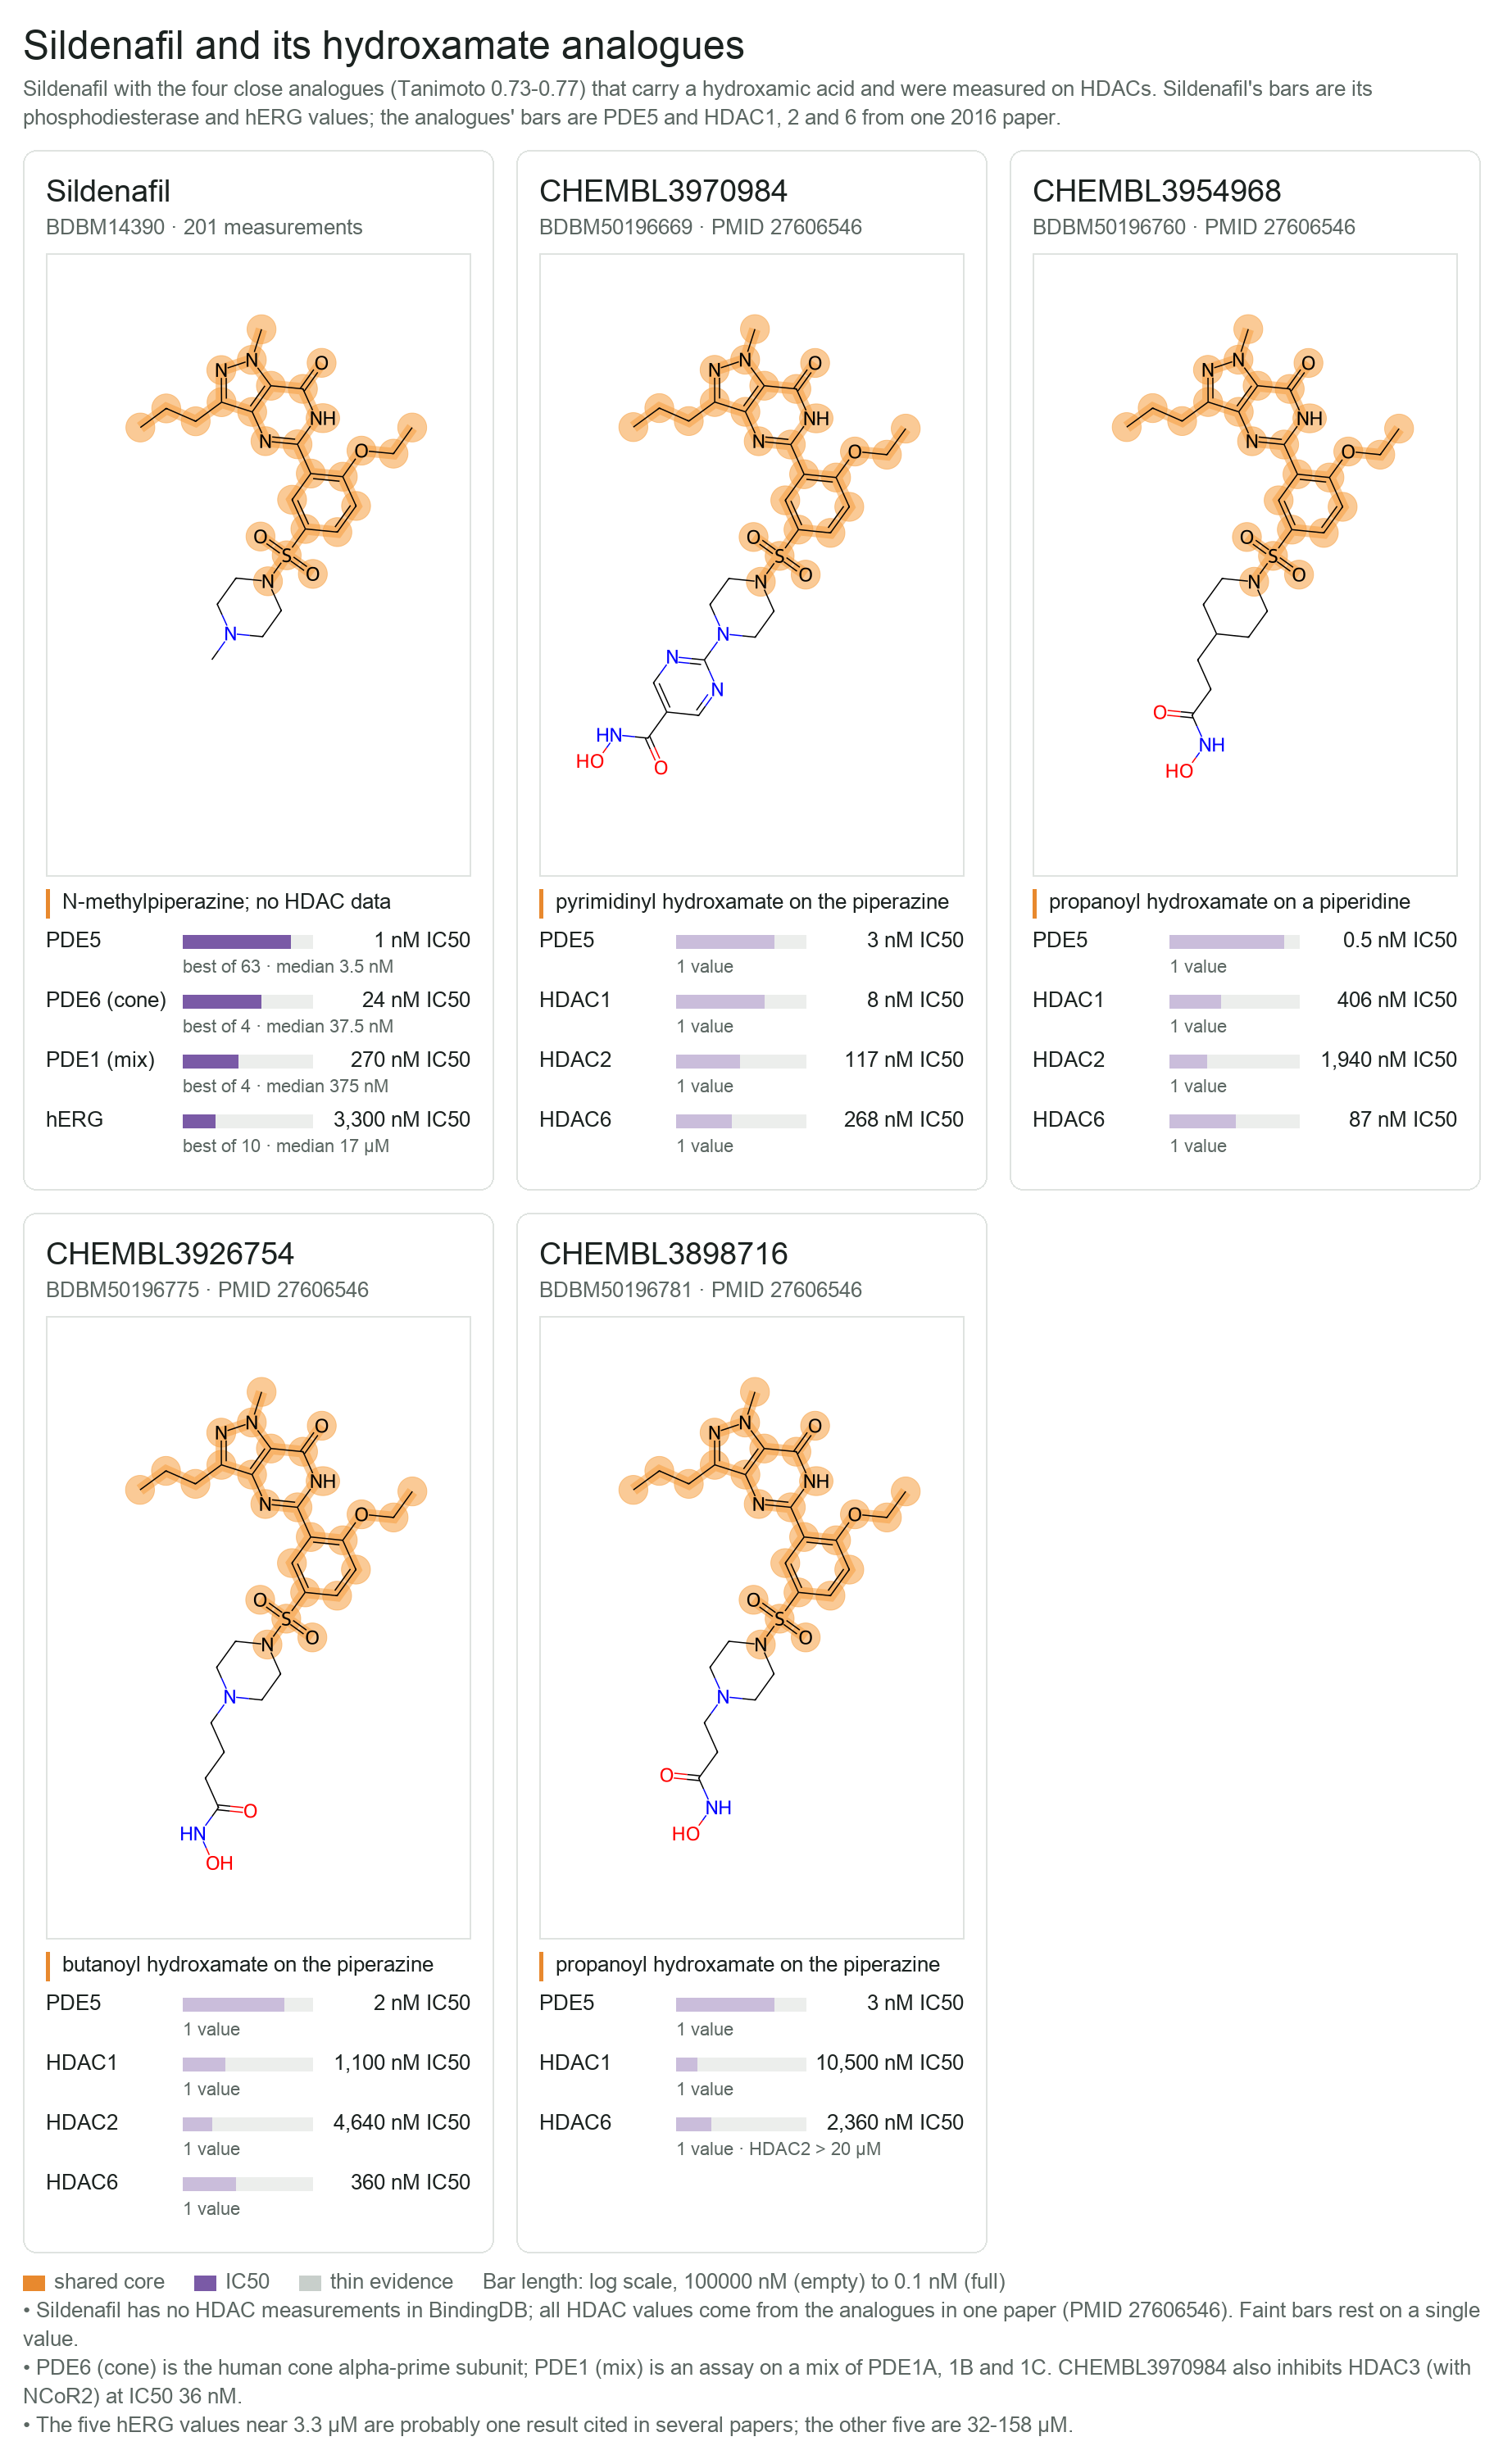

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Sildenafil and its hydroxamate analogues',
    'compounds': [
        {
            'smiles': 'CCCc1c2c(n(n1)C)C(=O)NC(=N2)c3cc(ccc3OCC)S(=O)(=O)N4CCN(CC4)C',
            'title': 'Sildenafil',
            'subtitle': 'BDBM14390 · 201 measurements',
            'caption': 'N-methylpiperazine; no HDAC data',
            'bars': [
                {'label': 'PDE5', 'value_nm': 1.0, 'type': 'IC50', 'note': 'best of 63 · median 3.5 nM'},
                {
                    'label': 'PDE6 (cone)',
                    'value_nm': 24.0,
                    'type': 'IC50',
                    'note': 'best of 4 · median 37.5 nM',
                },
                {
                    'label': 'PDE1 (mix)',
                    'value_nm': 270.0,
                    'type': 'IC50',
                    'note': 'best of 4 · median 375 nM',
                },
                {'label': 'hERG', 'value_nm': 3300.0, 'type': 'IC50', 'note': 'best of 10 · median 17 µM'},
            ],
        },
        {
            'smiles': 'CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(c5ncc(C(=O)NO)cn5)CC4)ccc3OCC)nc12',
            'title': 'CHEMBL3970984',
            'subtitle': 'BDBM50196669 · PMID 27606546',
            'caption': 'pyrimidinyl hydroxamate on the piperazine',
            'bars': [
                {'label': 'PDE5', 'value_nm': 3.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC1', 'value_nm': 8.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC2', 'value_nm': 117.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC6', 'value_nm': 268.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
            ],
        },
        {
            'smiles': 'CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCC(CCC(=O)NO)CC4)ccc3OCC)nc12',
            'title': 'CHEMBL3954968',
            'subtitle': 'BDBM50196760 · PMID 27606546',
            'caption': 'propanoyl hydroxamate on a piperidine',
            'bars': [
                {'label': 'PDE5', 'value_nm': 0.5, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC1', 'value_nm': 406.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC2', 'value_nm': 1940.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC6', 'value_nm': 87.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
            ],
        },
        {
            'smiles': 'CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(CCCC(=O)NO)CC4)ccc3OCC)nc12',
            'title': 'CHEMBL3926754',
            'subtitle': 'BDBM50196775 · PMID 27606546',
            'caption': 'butanoyl hydroxamate on the piperazine',
            'bars': [
                {'label': 'PDE5', 'value_nm': 2.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC1', 'value_nm': 1100.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC2', 'value_nm': 4640.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC6', 'value_nm': 360.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
            ],
        },
        {
            'smiles': 'CCCc1nn(C)c2c(=O)[nH]c(-c3cc(S(=O)(=O)N4CCN(CCC(=O)NO)CC4)ccc3OCC)nc12',
            'title': 'CHEMBL3898716',
            'subtitle': 'BDBM50196781 · PMID 27606546',
            'caption': 'propanoyl hydroxamate on the piperazine',
            'bars': [
                {'label': 'PDE5', 'value_nm': 3.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {'label': 'HDAC1', 'value_nm': 10500.0, 'type': 'IC50', 'note': '1 value', 'faint': True},
                {
                    'label': 'HDAC6',
                    'value_nm': 2360.0,
                    'type': 'IC50',
                    'note': '1 value · HDAC2 > 20 µM',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 3,
    'description': "Sildenafil with the four close analogues (Tanimoto 0.73-0.77) that carry a hydroxamic acid and were measured on HDACs. Sildenafil's bars are its phosphodiesterase and hERG values; the analogues' bars are PDE5 and HDAC1, 2 and 6 from one 2016 paper.",
    'notes': [
        'Sildenafil has no HDAC measurements in BindingDB; all HDAC values come from the analogues in one paper (PMID 27606546). Faint bars rest on a single value.',
        'PDE6 (cone) is the human cone alpha-prime subunit; PDE1 (mix) is an assay on a mix of PDE1A, 1B and 1C. CHEMBL3970984 also inhibits HDAC3 (with NCoR2) at IC50 36 nM.',
        'The five hERG values near 3.3 µM are probably one result cited in several papers; the other five are 32-158 µM.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Short answer: 35 compounds in BindingDB are close to sildenafil (BDBM14390, Tanimoto >= 0.7) and have measurements. Sildenafil itself is two of them, once as the free base and once as its citrate salt (BDBM50238854), so there are 33 analogues. Together they bind 40 targets at 10 uM or better. Apart from PDE5 itself, the hits fall into three groups, and only the first reflects sildenafil's own activity. The grid below shows sildenafil and the four analogues that matter for the second group, aligned on their shared 27-atom core (the pyrazolopyrimidinone-phenylsulfonyl-piperazine/piperidine framework), with bars for PDE5, the main off-targets and the HDACs.

**1. Other phosphodiesterases (a known class effect).** Sildenafil itself was measured against these, so the activity belongs to the drug. In the grid, its PDE5 IC50 is 1 nM at best and 3.5 nM as the median of 63 values; the cone PDE6 subunit is about 10x weaker (best 24 nM, median 37.5 nM of 4 values), which is the reason for the blue-tinted vision side effect; a PDE1A/1B/1C mix is about 100x weaker (best 270 nM, median 375 nM). The other phosphodiesterase values are not in the grid:

| Off-target | Best sildenafil IC50 | Comment |
|---|---|---|
| PDE6 rod/cone complexes and subunits | 9.5-140 nM | the 140 nM value is bovine rod PDE6 alpha |
| PDE1A, PDE1B (single isoforms) | 600 nM, 1.5 uM | one value each |
| PDE11A, PDE10A, PDE9A | 2.3-3.4 uM | weak |
| PDE4, PDE7A, PDE3 | 4.6-7.8 uM | weak |

**2. Histone deacetylases (HDAC1, 2, 3, 6), seen only in designed analogues.** These hits come from a 2016 J. Med. Chem. series (PMID 27606546). In that series a hydroxamic acid, a classic zinc-binding HDAC warhead, was attached to the sildenafil piperazine to make dual PDE5/HDAC inhibitors. Sildenafil has no measured HDAC activity in BindingDB. All four analogues keep PDE5 IC50 at 0.5-3 nM, but how much HDAC activity they gain depends on the linker, as the grid shows. The hydroxamate on a pyrimidine ring (CHEMBL3970984) is the strongest on HDAC1 (8 nM) and also hits HDAC3 (36 nM, not in the grid). A short propanoyl chain on the piperazine (CHEMBL3898716) is nearly inactive on HDAC1 (10.5 uM). Moving the same chain to a piperidine (CHEMBL3954968) or lengthening it to butanoyl (CHEMBL3926754) gives sub-micromolar HDAC6 but weak HDAC1, so those two lean towards HDAC6. Each value is a single measurement from that one paper.

**3. Weak or thin evidence on sildenafil.** Adenosine A2a receptor (Ki 200 nM, one measurement) and the ABCC5/MRP5 transporter (Ki 1.2 uM in one paper; a second paper reports IC50 80 uM) each rest on one report. Mouse IDO2 (4.5 uM) and the SARS-CoV-2 replicase (8.2 uM) are single screening values. The hERG channel KCNH2 has more data than it first appears: ten IC50 values, five at about 3.3 uM (probably one result cited in several papers) and five at 32-158 uM, median 17 uM. None of these needs worrying about at therapeutic exposure without further evidence.

Many "PDE5" rows in the target summary are the same enzyme in another species (rat, dog, cow) or a truncated construct (e.g. O76074[531-875]). They are not separate off-targets.

**Lesson:** an analogue's target is not the drug's target. Searching by similarity and then summarizing by target is a fast way to generate repurposing or off-target hypotheses, but it pools many compounds. Before you attribute a target to sildenafil, check which compound carries the measurement. The HDAC hits look striking in the summary (HDAC6 is the second-most common target, with 4 compounds), yet they come from analogues that were engineered to hit HDACs. The PDE6 and PDE1 hits, by contrast, are measured on sildenafil itself and match its known side-effect profile.

**How this was answered**

- `chemical_name_to_smiles` ("sildenafil"): resolved the name to BDBM14390 and its structure.
- `similarity_search` (threshold 0.7, `summarize_by_target=true`, `max_value_nm=10000`): grouped all close compounds by the targets they bind, giving 35 compounds and 40 targets.
- `similarity_search` (same threshold, no summary): listed the compounds themselves, which showed sildenafil's salt entry and the hydroxamic-acid series.
- `find_targets_for_compound` for sildenafil (`max_value_nm=10000`): its best value per target.
- `run_sql` on the activity table: every value of the four hydroxamate analogues, and the count and median of sildenafil's values on PDE5, PDE6, PDE1, hERG, A2a and ABCC5, to check which compound each off-target activity belongs to and how much data supports it.
- `draw_structure_grid`: sildenafil and the four hydroxamates with their PDE5, off-target and HDAC values, aligned on their 27-atom shared core.

**Try next**

- "Do tadalafil and vardenafil hit PDE6 as strongly as sildenafil?"
- "Which approved drugs bind hERG below 1 uM?" (Example 5.4)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 6 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 5.1 — From a drug to its analogues to their targets (sildenafil), 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```